### **0. Постановка задачи**

В данной работе рассматривается набор данных, содержащий информацию об объявлениях об аренде жилья в Нью-Йорке в 2019 году. В нём 48895 записей и 16 признаков:


&emsp;`id` — номер объявления;  
&emsp;`name` — название объявления;   
&emsp;`host_id` — номер арендодателя;  
&emsp;`host_name` — имя арендодателя;  
&emsp;`neighbourhood_group` — административный округ;  
&emsp;`neighbourhood` — конкретный микрорайон;  
&emsp;`latitude` — широта;  
&emsp;`longitude` — долгота;  
&emsp;`room_type` — тип жилья;  
&emsp;`price` — цена за сутки;  
&emsp;`minimum_nights` — минимальное количество ночей;  
&emsp;`number_of_reviews` — общее количество отзывов;  
&emsp;`last_review` — дата последнего отзыва;  
&emsp;`reviews_per_month` — среднее количество отзывов в месяц;  
&emsp;`calculated_host_listings_count` — количество объявлений у данного арендодателя;  
&emsp;`availability_365` — количество дней, в течение которых жильё доступно для бронирования.


Используя этот набор данных, рассмотрим задачу регрессии — предсказание суточной стоимости аренды жилья по следующим его характеристикам: местоположению, типу жилья, типу арендодателя, активности отзывов, минимальному сроку бронирования и общему количеству дней, доступных для аренды в течение года.

### **1. Загрузка данных**

In [110]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [128]:
url = "https://raw.githubusercontent.com/isakovaolga/ML/main/AB_NYC_2019.csv"
data = pd.read_csv(url)

In [129]:
data.shape

(48895, 16)

In [5]:
data

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [7]:
data.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


**Удалим столбцы, которые не подходят для решения задачи регрессии,** так как не влияют на стоимость суточной аренды:  
**id** (номер объявления) — уникальный идентификатор записи в наборе данных;  
**name** (название объявления) — произвольный рекламный текст;  
**host_id** (номер арендодателя), **host_name** (имя арендодателя) — уникальный идентификатор арендодателя и его имя, при этом полезная информация о каждом арендодателе содержится в столбце calculated_host_listings_count (количество объявлений у данного арендодателя), который показывает, кто сдаёт жильё: крупное агентство недвижимости или частное лицо;  
**last_review** (дата последнего отзыва) — содержит 10 052 пропуска, при этом активность и качество жилья полноценно описываются столбцами с общим количеством отзывов и количеством отзывов в месяц.

In [130]:
columns_to_drop = ["id", "name", "host_id", "host_name", "last_review"]
data = data.drop(columns=columns_to_drop)

In [131]:
data.shape

(48895, 11)

In [10]:
data.head()

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,0.21,6,365
1,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355
2,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,1,365
3,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194
4,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,0.10,1,0


### **2. Разделение данных на обучающую и тестовую выборки**

In [132]:
from sklearn.model_selection import train_test_split
X = data.drop(columns=["price"])
y = data["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print(f"Обучающая выборка: {X_train.shape}")
print(f"Тестовая выборка: {X_test.shape}")

Обучающая выборка: (36671, 10)
Тестовая выборка: (12224, 10)


### **3. Визуализизация данных и вычисление основных характеристик. Интерпретация**

Информация о числовых признаках:

In [133]:
train_data = X_train.copy()
train_data["price"] = y_train
train_data.describe()

,latitude,longitude,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,price
count,36671.000000,36671.000000,36671.000000,36671.000000,29080.000000,36671.000000,36671.000000,36671.000000
mean,40.728863,-73.952265,7.164899,23.285266,1.378707,7.193286,113.202912,153.951106
std,0.054468,0.045960,21.597809,44.410726,1.691161,33.211129,131.669821,250.994064
min,40.499790,-74.242850,1.000000,0.000000,0.010000,1.000000,0.000000,0.000000
25%,40.689980,-73.983045,1.000000,1.000000,0.190000,1.000000,0.000000,69.000000
50%,40.723020,-73.955700,3.000000,5.000000,0.730000,1.000000,45.000000,107.000000
75%,40.763120,-73.936430,5.000000,24.000000,2.020000,2.000000,227.000000,175.000000
max,40.913060,-73.712990,1250.000000,629.000000,58.500000,327.000000,365.000000,10000.000000


Информация о категориальных признаках:

In [14]:
train_data.describe(include=['object'])

,neighbourhood_group,neighbourhood,room_type
count,36671,36671,36671
unique,5,219,3
top,Manhattan,Williamsburg,Entire home/apt
freq,16272,2955,19078


In [134]:
from IPython.display import display
df_neighbourhood_group = train_data['neighbourhood_group'].value_counts().reset_index()
df_neighbourhood_group.columns = ['neighbourhood_group', 'Количество']
df_neighbourhood_group['Доля, %'] = (df_neighbourhood_group['Количество'] / len(train_data) * 100).round(2)
display(df_neighbourhood_group)

,neighbourhood_group,Количество,"Доля, %"
0,Manhattan,16272,44.37
1,Brooklyn,15110,41.20
2,Queens,4215,11.49
3,Bronx,804,2.19
4,Staten Island,270,0.74


In [135]:
df_room_type = train_data['room_type'].value_counts().reset_index()
df_room_type.columns = ['room_type', 'Количество']
df_room_type['Доля, %'] = (df_room_type['Количество'] / len(train_data) * 100).round(2)
display(df_room_type)

,room_type,Количество,"Доля, %"
0,Entire home/apt,19078,52.02
1,Private room,16727,45.61
2,Shared room,866,2.36


In [46]:
df_neighbourhood= train_data['neighbourhood'].value_counts().reset_index()
df_neighbourhood.columns = ['neighbourhood (топ 10)', 'Количество']
df_neighbourhood['Доля, %'] = (df_neighbourhood['Количество'] / len(train_data) * 100).round(2)
display(df_neighbourhood)

,neighbourhood (топ 10),Количество,"Доля, %"
0,Williamsburg,2955,8.06
1,Bedford-Stuyvesant,2816,7.68
2,Harlem,1991,5.43
3,Bushwick,1827,4.98
4,Upper West Side,1493,4.07
...,...,...,...
214,Fort Wadsworth,1,0.00
215,Lighthouse Hill,1,0.00
216,"Bay Terrace, Staten Island",1,0.00
217,Richmondtown,1,0.00


Распределение стоимости:

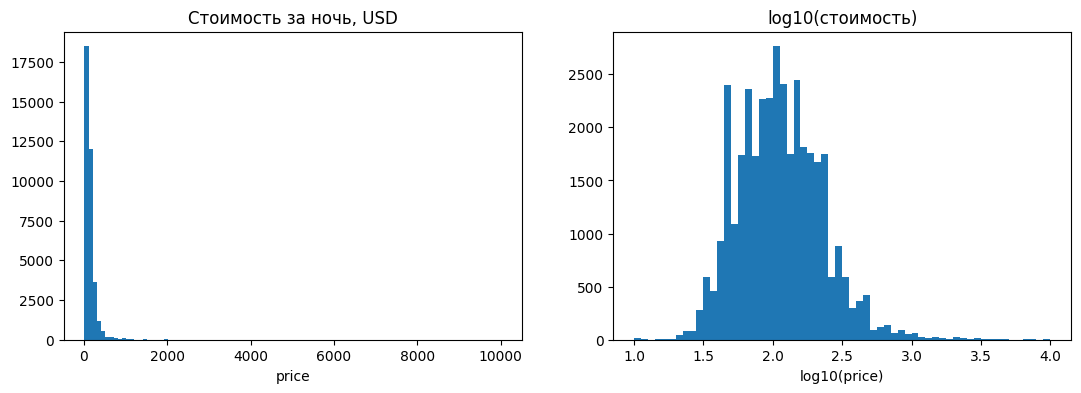

In [30]:
prices_positive = train_data[train_data['price'] > 0]['price']
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(prices_positive, bins=100)
ax[0].set_title('Стоимость за ночь, USD')
ax[0].set_xlabel('price')
ax[1].hist(np.log10(prices_positive), bins=60)
ax[1].set_title('log10(стоимость)')
ax[1].set_xlabel('log10(price)')
pass

In [36]:
print(f"Количество жилья с нулевой ценой: {len(train_data[train_data['price'] == 0])}")

Количество жилья с нулевой ценой: 9


Распределение стоимости суточной аренды имеет правостороннюю асимметрию. Медианная цена равна 107 USD, а среднее значение равно 152 USD. Это связано с тем, что есть несколько очень дорогих объектов для аренды. При переходе к десятичному логарифму распределение становится близким к нормальному с вершиной 2.0, что равняется цене в 100 USD.

Зависимость цены от различных признаков:

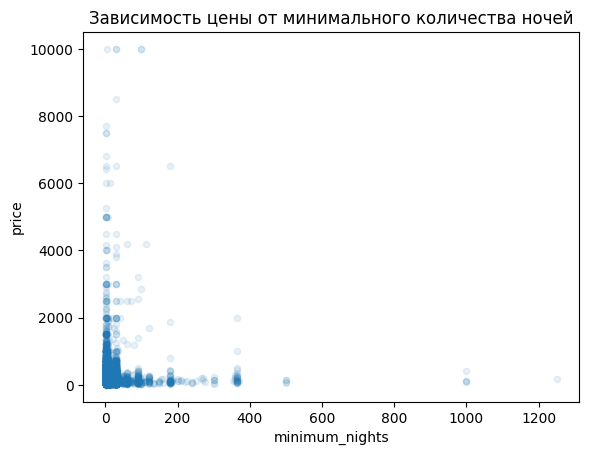

In [48]:
train_data.plot(kind='scatter', x='minimum_nights', y='price', alpha=0.1)
plt.title('Зависимость цены от минимального количества ночей')
pass

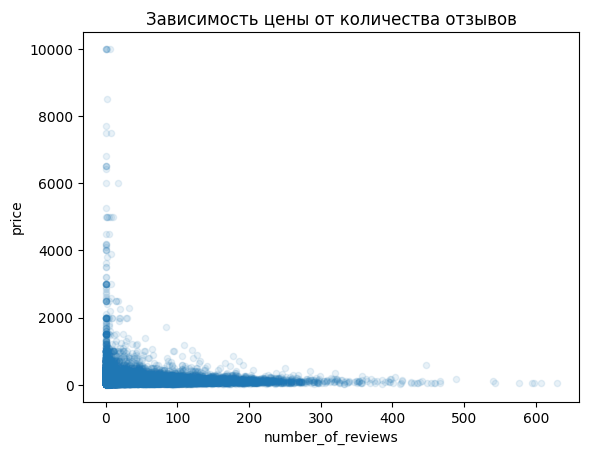

In [47]:
train_data.plot(kind='scatter', x='number_of_reviews', y='price', alpha=0.1)
plt.title('Зависимость цены от количества отзывов')
pass

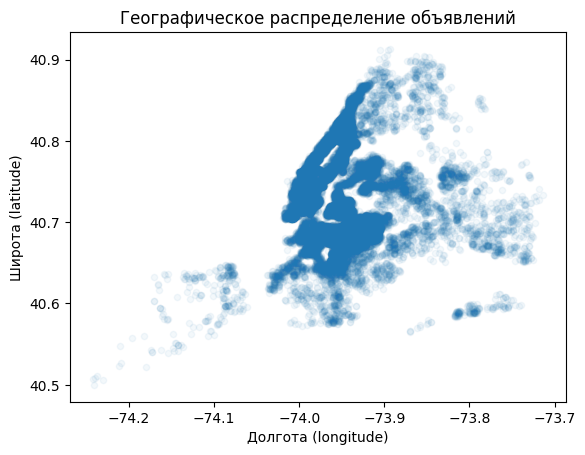

In [51]:
train_data.plot(kind='scatter', x='longitude', y='latitude', alpha=0.05)
plt.title('Географическое распределение объявлений')
plt.xlabel('Долгота (longitude)')
plt.ylabel('Широта (latitude)')
pass

Все диаграммы рассеивания:

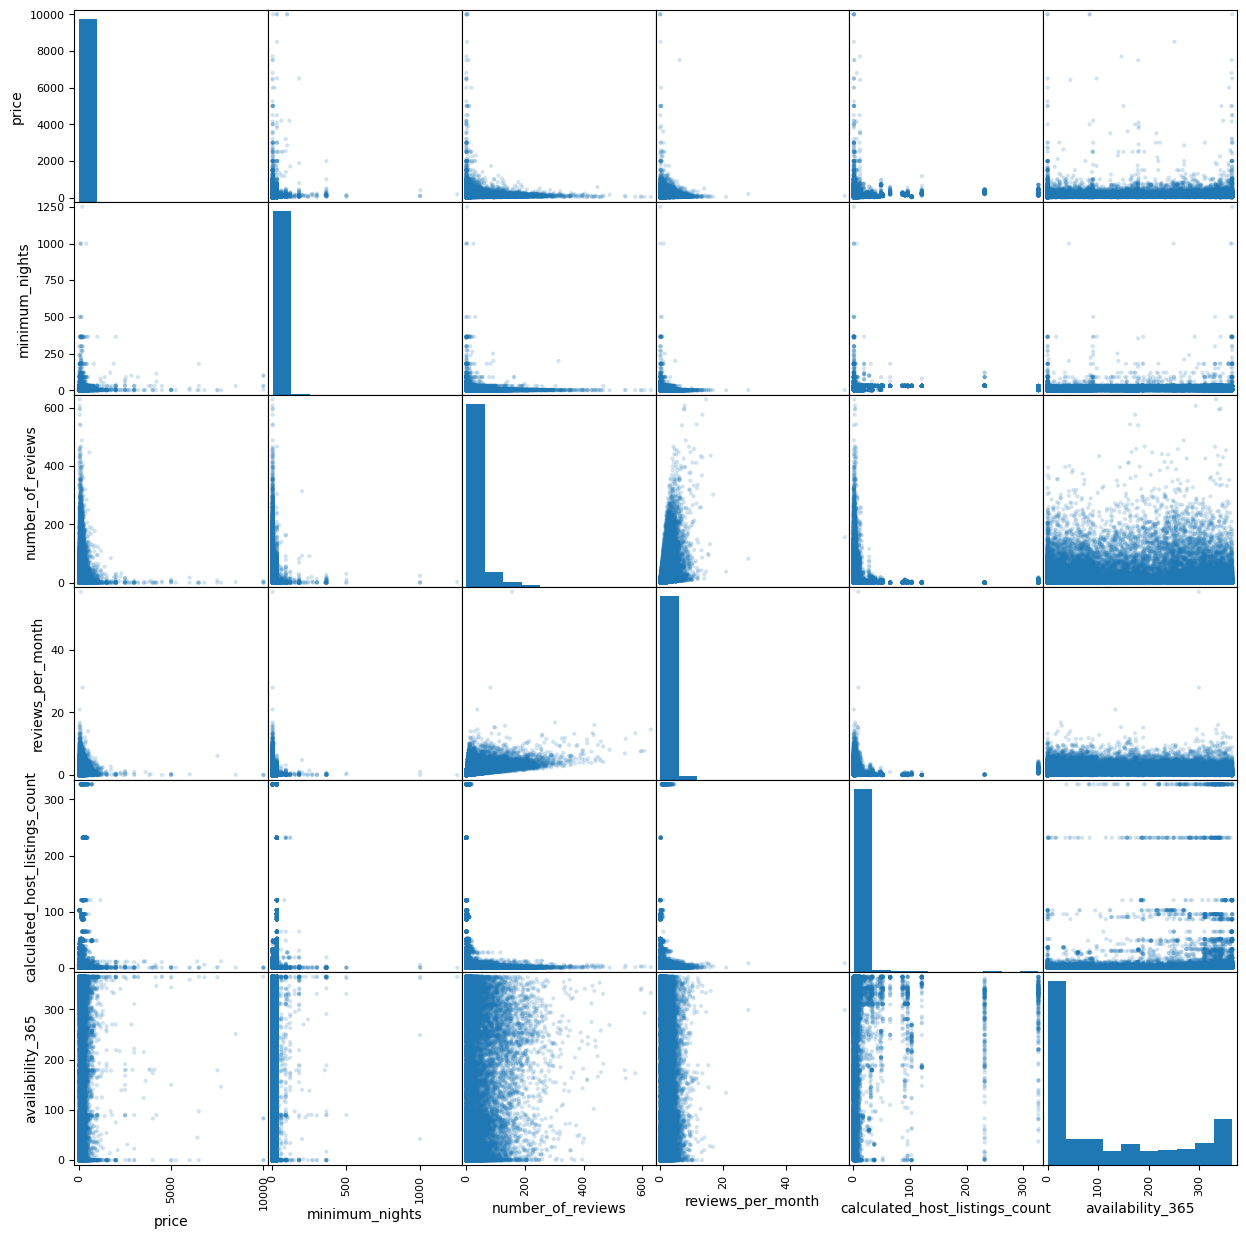

In [61]:
numeric_features = ['price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
pd.plotting.scatter_matrix(train_data[numeric_features],  figsize=(15, 15), alpha=0.2, diagonal='hist')
pass

Все диаграммы рассеивания для случайных 1000 строк с отображенением типа жилья:

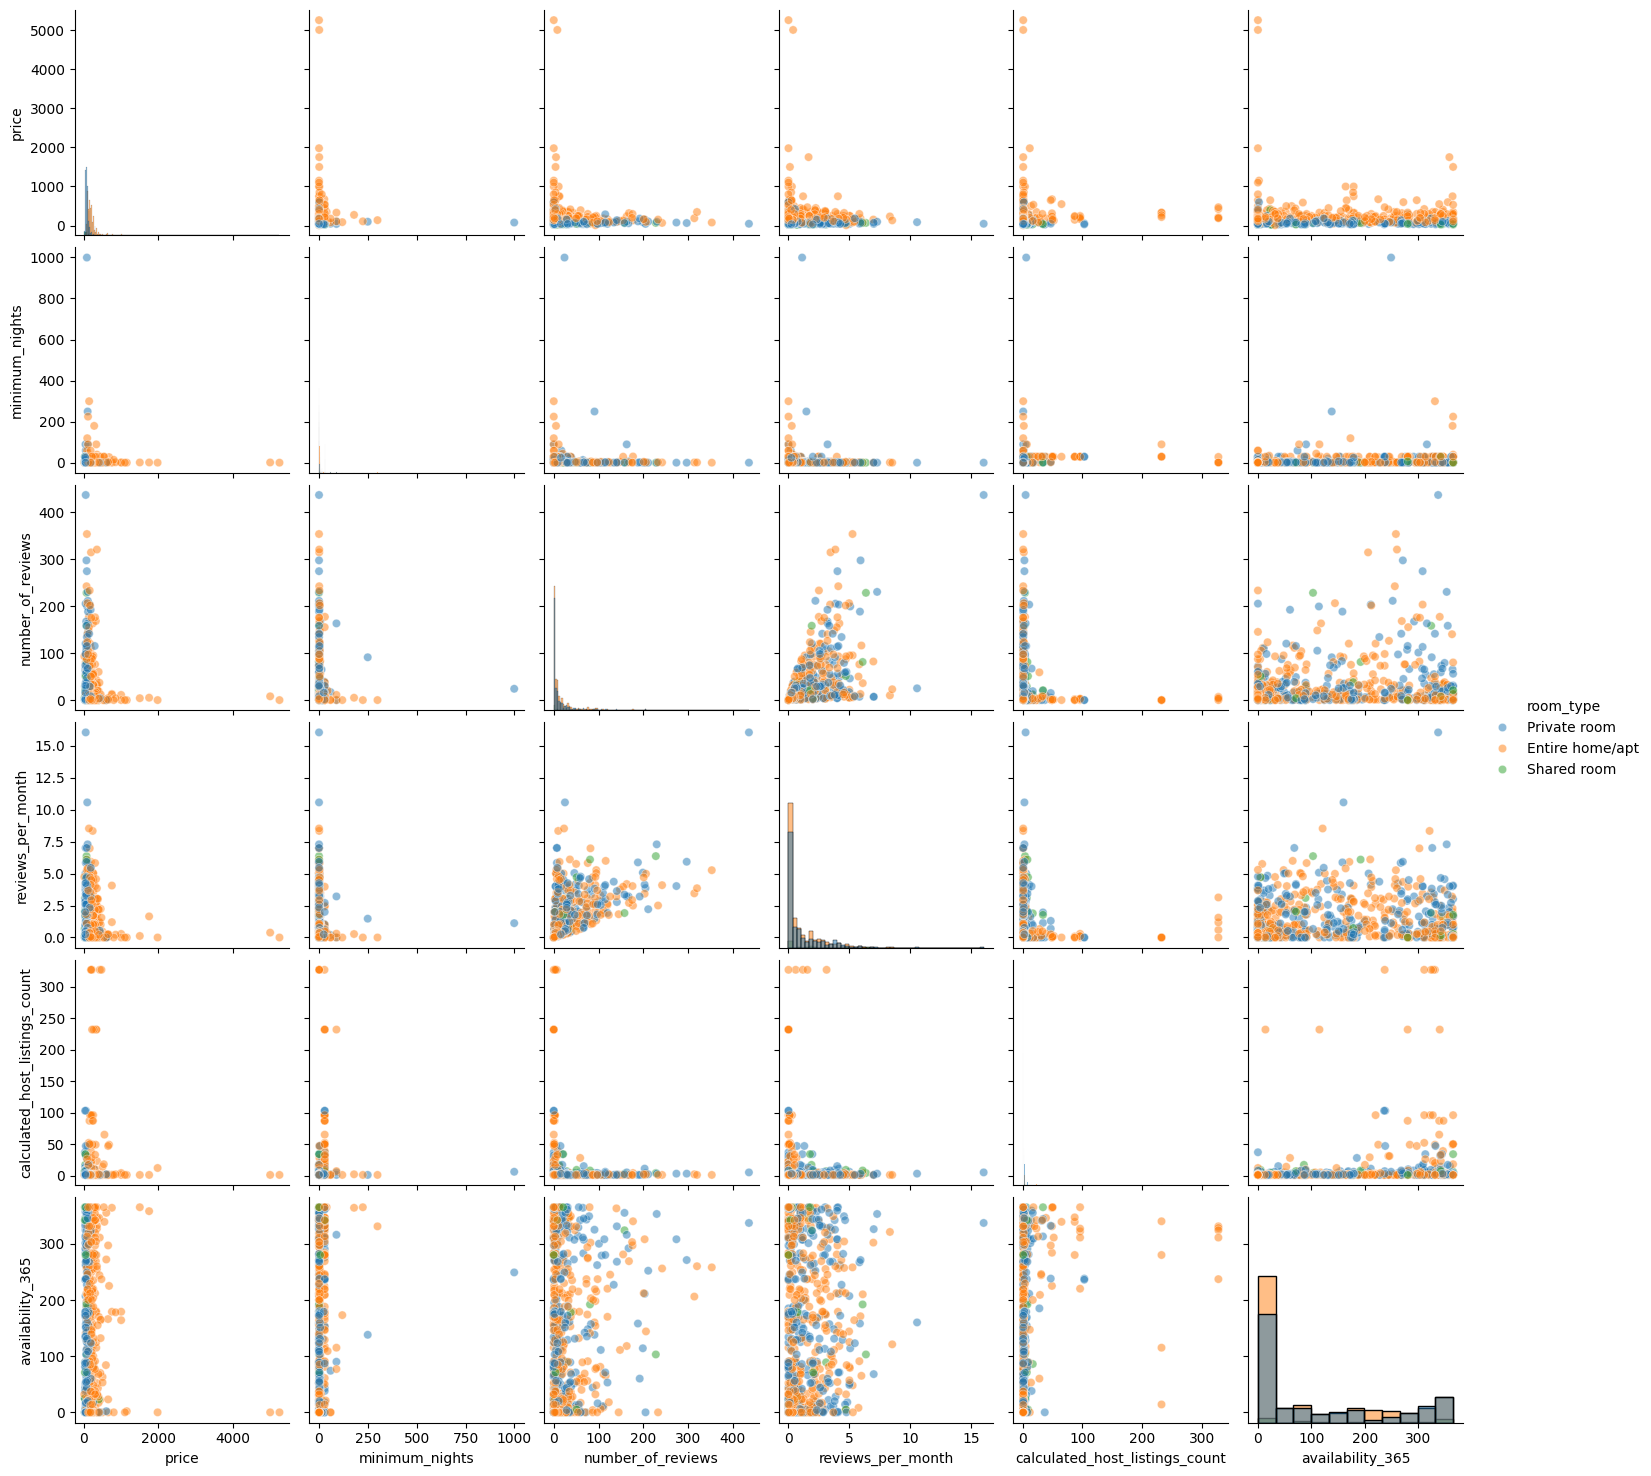

In [58]:
full_features = ['price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365','room_type']
df_pairplot = train_data[full_features].sample(1000, random_state=42).copy()
df_pairplot['reviews_per_month'] = df_pairplot['reviews_per_month'].fillna(0)
sns.pairplot(df_pairplot, hue='room_type', diag_kind='hist', plot_kws={'alpha': 0.5})
pass

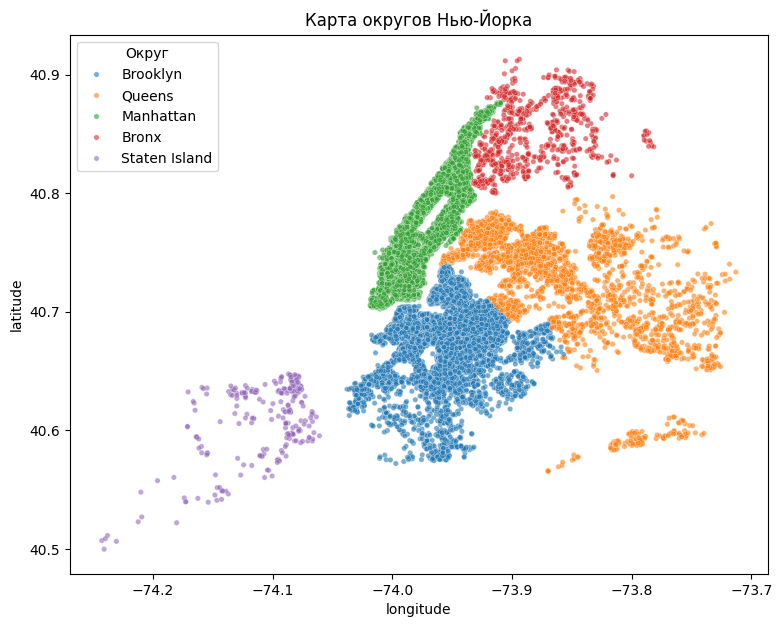

In [63]:
plt.figure(figsize=(9, 7))
sns.scatterplot(
    x='longitude', y='latitude',
    hue='neighbourhood_group',
    data=train_data,
    alpha=0.6, s=15
)
plt.title('Карта округов Нью-Йорка')
plt.legend(title='Округ')
pass

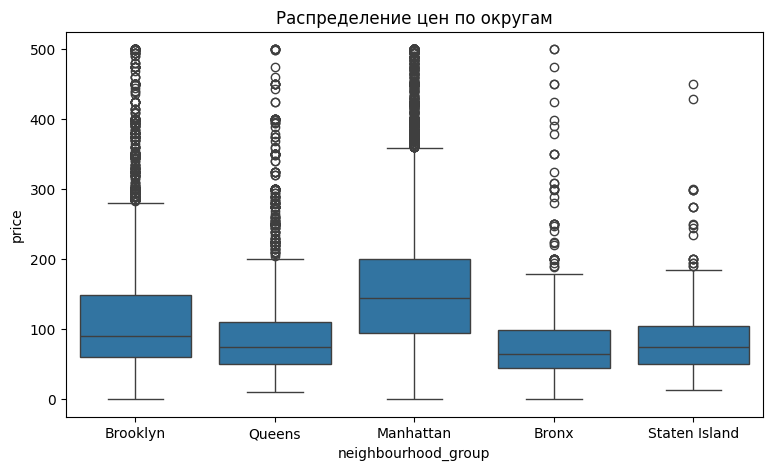

In [65]:
plt.figure(figsize=(9, 5))
sns.boxplot(x='neighbourhood_group', y='price', data=train_data[train_data['price'] <= 500])
plt.title('Распределение цен по округам')
plt.xlabel('neighbourhood_group')
plt.ylabel('price')
pass

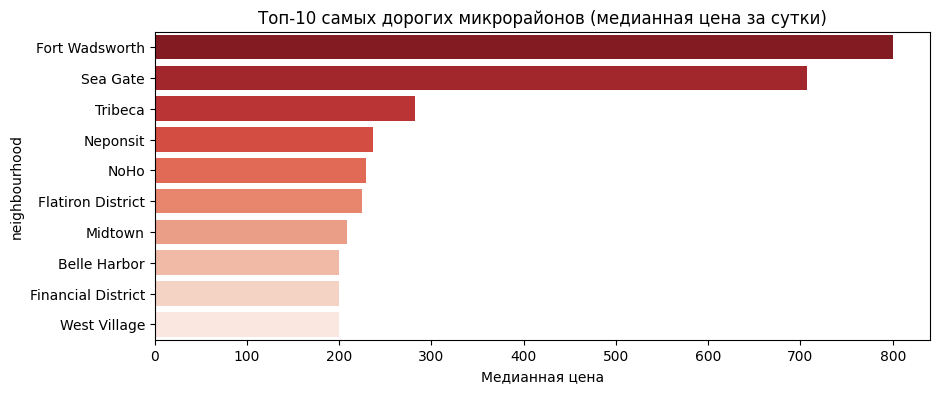

In [103]:
top_expensive_neigh = train_data.groupby('neighbourhood')['price'].median().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 4))
sns.barplot(
    x=top_expensive_neigh.values,
    y=top_expensive_neigh.index,
    hue=top_expensive_neigh.index,
    palette='Reds_r',
    legend=False
)
plt.title('Топ-10 самых дорогих микрорайонов (медианная цена за сутки)')
plt.xlabel('Медианная цена')
plt.ylabel('neighbourhood')
pass

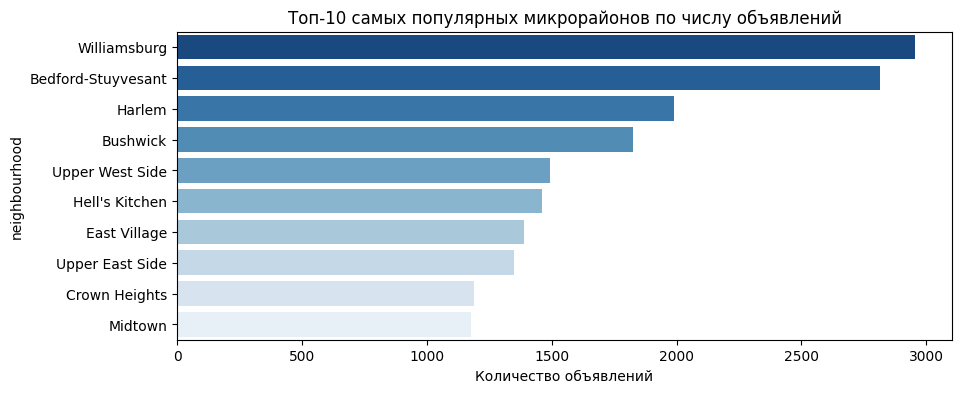

In [70]:
top_popular_neigh = train_data['neighbourhood'].value_counts().head(10)
plt.figure(figsize=(10, 4))
sns.barplot(
    x=top_popular_neigh.values,
    y=top_popular_neigh.index,
    hue=top_popular_neigh.index,
    palette='Blues_r',
    legend=False
)
plt.title('Топ-10 самых популярных микрорайонов по числу объявлений')
plt.xlabel('Количество объявлений')
plt.ylabel('neighbourhood')
pass

На диаграммах рассеивания цены против остальных числовых признаков точки не ложатся на прямую линию, что показывает отсутствие линейной связи. Самое дорогое жильё находится в округе `Manhattan`, а самое доступное — в `Bronx` и `Staten Island`. Аренда всего жилья целиком `Entire home/apt` стоит дороже, чем отдельные комнаты `Private room` и общие комнаты `Shared room`. Основная часть предложений сосредоточена в `Williamsburg` и `Bedford-Stuyvesant`. Самое дорогое жильё по медианной цене находится в микрорайонах `Fort Wadsworth` и `Sea Gate`.

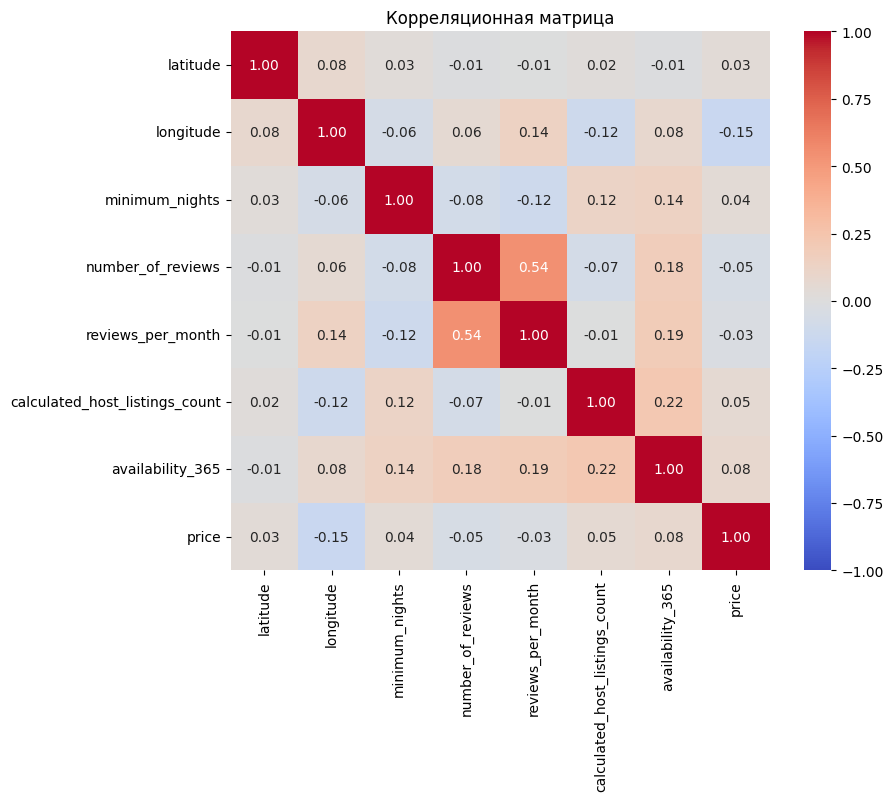

In [71]:
corr_mat = train_data.corr(numeric_only=True)
plt.figure(figsize=(9, 7))
sns.heatmap(corr_mat, square=True, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Корреляционная матрица')
pass

In [79]:
print(f"Пары признаков с заметной корреляцией:")
corr_mat.where(np.triu(np.abs(corr_mat) > 0.3, k=1)).stack().sort_values(ascending=False)

Пары признаков с заметной корреляцией:


,,0
number_of_reviews,reviews_per_month,0.544894


Линейная корреляция входных признаков с целевой переменной `price` очень слабая, поэтому зависимость между ценой и характеристиками жилья имеет сложный нелинейный характер. Но в обучающей выборке есть заметная корелляция между количеством отзывов `number_of_reviews` и средней активностью отзывов в месяц `reviews_per_month`, так как оба эти признака характеризуют частоту аренды жилья.

### **4. Выбросы**

Возможные ошибки ввода: `price == 0` (жильё не может сдаваться бесплатно) и `minimum_nights > 365` (минимальный срок бронирования больше года для посуточной аренды невозможен).  
Экстремальные выбросы: объекты с ценой в несколько тысяч долларов (до 10 000).

In [136]:
print("Топ-10 максимальных значений minimum_nights:")
display(train_data['minimum_nights'].sort_values(ascending=False).head(10))
print("\nКвантили price:")
display(train_data['price'].quantile([0.001, 0.01, 0.5, 0.95, 0.99, 0.995, 0.999]))
print("\nКвантили minimum_nights:")
display(train_data['minimum_nights'].quantile([0.5, 0.9, 0.95, 0.99, 0.995, 0.999]))

Топ-10 максимальных значений minimum_nights:


,minimum_nights
5767,1250
2854,1000
13404,999
26341,999
38664,999
47620,500
8014,500
7355,500
11193,500
1305,370



Квантили price:


,price
0.001,19.00
0.010,30.00
0.500,107.00
0.950,360.50
0.990,799.00
0.995,1066.65
0.999,3309.66



Квантили minimum_nights:


,minimum_nights
0.500,3.00
0.900,29.00
0.950,30.00
0.990,50.00
0.995,90.00
0.999,355.98


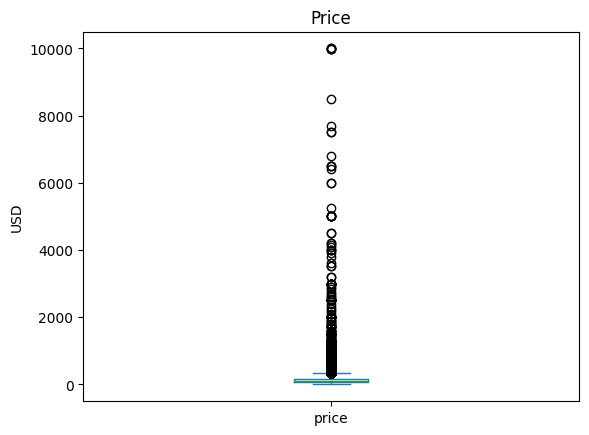

In [81]:
train_data['price'].plot(kind='box')
plt.title('Price')
plt.ylabel('USD')
pass

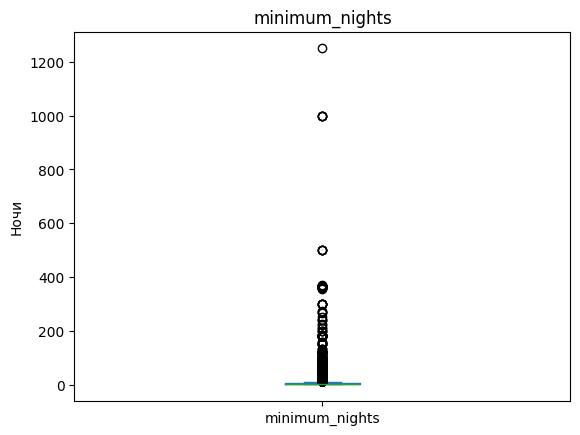

In [82]:
train_data['minimum_nights'].plot(kind='box')
plt.title('minimum_nights')
plt.ylabel('Ночи')
pass

По правилу Тьюки выбросами считаются все точки за пределами $[Q_1 - 1.5 \times \text{IQR},\, Q_3 + 1.5 \times \text{IQR}]$. Проверим, какие границы оно дает для цены.

In [137]:
Q1, Q3 = train_data['price'].quantile([0.25, 0.75])
IQR = Q3 - Q1
price_lower = Q1 - 1.5 * IQR
price_upper = Q3 + 1.5 * IQR
print(f"Нижняя граница по Тьюки: {price_lower}")
print(f"Верхняя граница по Тьюки: {price_upper}")
outliers_count = (train_data['price'] > price_upper).sum()
print(f"Количество записей выше границы Тьюки: {outliers_count} ({outliers_count / len(train_data) * 100:.2f}%)")

Нижняя граница по Тьюки: -90.0
Верхняя граница по Тьюки: 334.0
Количество записей выше границы Тьюки: 2276 (6.21%)


Верхняя граница по Тьюки составляет около 334. Если отсечь всё, что выше этой суммы, то удалится почти 6.21% обучающей выборки, включая квартиры бизнес-класса за нормальную цену, не завышенную. Поэтому этот метод лучше не использовать.  
Вместо этого можно рассмотреть квантили и удалить бесплатные варианты `price >= 10`, ограничить экстремальный правый хвост цены 99.5%-м квантилем (1066.65 USD), ограничить минимальное число ночей логичным порогом: `minimum_nights <= 365`.

In [138]:
price_limit = train_data['price'].quantile(0.995)
mask = (
    (train_data['price'] >= 10) &
    (train_data['price'] <= price_limit) &
    (train_data['minimum_nights'] <= 365)
)
print(f"Строк до очистки: {len(train_data)}")
train_clean = train_data[mask].copy()
print(f"Строк после очистки: {len(train_clean)}")
print(f"Удалено строк: {len(train_data) - len(train_clean)} ({(len(train_data) - len(train_clean)) / len(train_data) * 100:.2f}%)")
X_train = train_clean.drop(columns=['price'])
y_train = train_clean['price']

Строк до очистки: 36671
Строк после очистки: 36468
Удалено строк: 203 (0.55%)


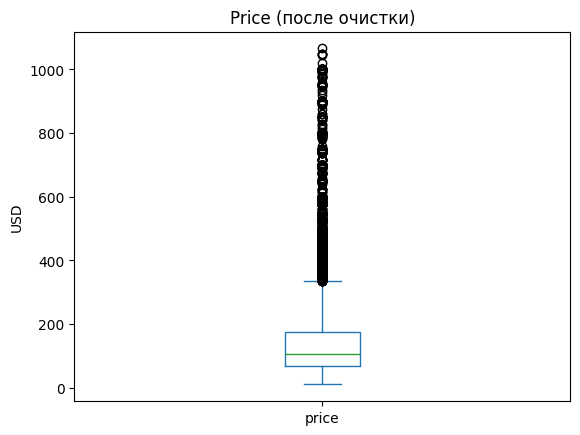

In [91]:
train_clean['price'].plot(kind='box')
plt.title('Price (после очистки)')
plt.ylabel('USD')
pass

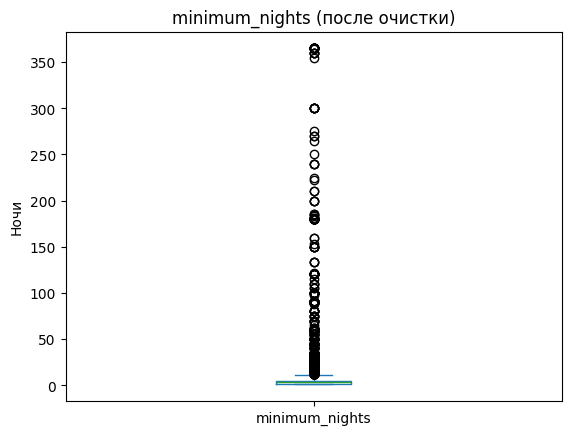

In [92]:
train_clean['minimum_nights'].plot(kind='box')
plt.title('minimum_nights (после очистки)')
plt.ylabel('Ночи')
pass

### **5. Обработка пропущенных значений**

In [139]:
print("Пропуски в обучающей выборке:\n")
print(X_train.isna().sum())

print("\n\nПропуски в тестовой выборке:\n")
print(X_test.isna().sum())

Пропуски в обучающей выборке:

neighbourhood_group                  0
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
minimum_nights                       0
number_of_reviews                    0
reviews_per_month                 7481
calculated_host_listings_count       0
availability_365                     0
dtype: int64


Пропуски в тестовой выборке:

neighbourhood_group                  0
neighbourhood                        0
latitude                             0
longitude                            0
room_type                            0
minimum_nights                       0
number_of_reviews                    0
reviews_per_month                 2461
calculated_host_listings_count       0
availability_365                     0
dtype: int64


In [107]:
print("Строки, где 0 отзывов:\n")
display(train_data[train_data['number_of_reviews'] == 0][['number_of_reviews', 'reviews_per_month']].head(5))
print("\n\nСтроки, где отзывы есть:\n")
display(train_data[train_data['number_of_reviews'] > 0][['number_of_reviews', 'reviews_per_month']].head(5))

Строки, где 0 отзывов:



,number_of_reviews,reviews_per_month
41630,0,NaN
42725,0,NaN
45335,0,NaN
12668,0,NaN
6326,0,NaN




Строки, где отзывы есть:



,number_of_reviews,reviews_per_month
542,207,2.18
18954,1,0.04
3852,17,0.39
34822,42,4.00
6002,1,0.02


Пропуски содержатся только в столбце `reviews_per_month` (среднее количество отзывов в месяц). Это возникло в тех строках, где у жилья ещё нет отзывов (`number_of_reviews == 0`). Поэтому нужно заполнить эти пропуски числом 0.

In [140]:
from sklearn.impute import SimpleImputer
imputer_reviews = SimpleImputer(strategy='constant', fill_value=0)
imputer_reviews.fit(X_train[['reviews_per_month']])
X_train['reviews_per_month'] = imputer_reviews.transform(X_train[['reviews_per_month']])
X_test['reviews_per_month'] = imputer_reviews.transform(X_test[['reviews_per_month']])
print("Пропуски в обучающей выборке:", X_train.isna().sum().sum())
print("Пропуски в тестовой выборке:", X_test.isna().sum().sum())

Пропуски в обучающей выборке: 0
Пропуски в тестовой выборке: 0


### **6. Обработка категориальных признаков**

Исключим из рассмотрения признак `neighbourhood` (микрорайон), так как он содержит 221 уникальное значение, и его бинаризация приведёт к сильному раздуванию размерности, что критично для алгоритма $k\text{NN}$. При этом точное местоположение объекта уже представлено координатами `latitude` и `longitude` и округом `neighbourhood_group`. К остальным категориальным признакам `neighbourhood_group` (округ) и `room_type` (тип жилья) применим метод бинаризации.

In [141]:
from sklearn.preprocessing import OneHotEncoder
X_train = X_train.drop(columns=['neighbourhood'])
X_test = X_test.drop(columns=['neighbourhood'])
from sklearn.preprocessing import OneHotEncoder
enc = OneHotEncoder(drop='if_binary', sparse_output=False)
cat_cols = ['neighbourhood_group', 'room_type']
enc.fit(X_train[cat_cols])
dummies_train = pd.DataFrame(
    enc.transform(X_train[cat_cols]),
    columns=enc.get_feature_names_out(cat_cols),
    index=X_train.index
)
X_train = pd.concat((X_train, dummies_train), axis=1).drop(cat_cols, axis=1)
dummies_test = pd.DataFrame(
    enc.transform(X_test[cat_cols]),
    columns=enc.get_feature_names_out(cat_cols),
    index=X_test.index
)
X_test = pd.concat((X_test, dummies_test), axis=1).drop(cat_cols, axis=1)
print(f"Размерность обучающей выборки после бинаризации: {X_train.shape}")
print(f"Размерность тестовой выборки после бинаризации: {X_test.shape}")
display(X_train.head())

Размерность обучающей выборки после бинаризации: (36468, 15)
Размерность тестовой выборки после бинаризации: (12224, 15)


,latitude,longitude,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Bronx,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Entire home/apt,room_type_Private room,room_type_Shared room
542,40.68497,-73.95592,3,207,2.18,1,304,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
18954,40.59324,-73.77288,30,1,0.04,43,354,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3852,40.67026,-73.92587,2,17,0.39,1,0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
34822,40.85268,-73.92716,1,42,4.00,1,2,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
41630,40.88474,-73.90321,30,0,0.00,37,0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


### **7. Нормализация**

Перед применением метода $k$ ближайших соседей $k\text{NN}$) необходимо привести все признаки к единому масштабу. Сейчас признаки имеют разные смыслы и разные диапазоны: количество доступных дней `availability_365` меняется от 0 до 365, а координаты `latitude` — от 40.5 до 40.9, `longitude` — от -74.2 до -73.7. Без масштабирования алгоритм $k\text{NN}$, вычисляющий евклидово р асстояние, будет ориентироваться только на признаки с наибольшим абсолютным размахом. Применим стандартизацию, которая приводит каждый признак к нулевому среднему и единичному стандартному отклонению.

In [142]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)
X_train = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)
X_train.describe().round(3)

,latitude,longitude,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Bronx,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Entire home/apt,room_type_Private room,room_type_Shared room
count,36468.000,36468.000,36468.000,36468.000,36468.000,36468.000,36468.000,36468.000,36468.000,36468.000,36468.000,36468.000,36468.000,36468.000,36468.000
mean,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000,0.000,0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
min,-4.202,-6.321,-0.353,-0.525,-0.682,-0.187,-0.858,-0.150,-0.839,-0.891,-0.361,-0.086,-1.039,-0.918,-0.156
25%,-0.714,-0.669,-0.353,-0.503,-0.657,-0.187,-0.858,-0.150,-0.839,-0.891,-0.361,-0.086,-1.039,-0.918,-0.156
50%,-0.108,-0.076,-0.233,-0.413,-0.452,-0.187,-0.516,-0.150,-0.839,-0.891,-0.361,-0.086,0.963,-0.918,-0.156
75%,0.629,0.345,-0.114,0.014,0.312,-0.157,0.861,-0.150,1.192,1.123,-0.361,-0.086,0.963,1.089,-0.156
max,3.380,5.200,21.391,13.610,35.685,9.605,1.918,6.669,1.192,1.123,2.770,11.600,0.963,1.089,6.431


### **8. Метод k ближайших соседей**

In [143]:
mask_test = (y_test >= 10) & (y_test <= price_limit)
X_test = X_test.loc[mask_test]
y_test = y_test.loc[mask_test]
print(f"Размер обучающей выборки: {X_train.shape[0]}")
print(f"Размер тестовой выборки: {X_test.shape[0]}")

Размер обучающей выборки: 36468
Размер тестовой выборки: 12174


Для решения задачи регрессии был выбран метод $k$ ближайших соседей $k\text{NN}$, потому что:
* стоимость жилья одного типа в одном и том же микрорайоне похожа между собой, а у нас есть точные координаты всех помещений, по которым этот метод сможет найти наиболее близкие аналоги и усреднить их стоимость;
* отсутствует линейная зависимость между ценой аренды жилья и его характеристиками, а этот метод может аппроксимировать сложные нелинейные поверхности.

In [149]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
knn_model = KNeighborsRegressor(n_neighbors=10, n_jobs=-1)
knn_model.fit(X_train, y_train)
y_train_pred = knn_model.predict(X_train)
y_test_pred  = knn_model.predict(X_test)
rmse_train = mean_squared_error(y_train, y_train_pred)**0.5
rmse_test  = mean_squared_error(y_test, y_test_pred)**0.5
mae_train = mean_absolute_error(y_train, y_train_pred)
mae_test  = mean_absolute_error(y_test, y_test_pred)
r2_train = r2_score(y_train, y_train_pred)
r2_test  = r2_score(y_test, y_test_pred)
results_knn = pd.DataFrame({
    'Train': [rmse_train, mae_train, r2_train],
    'Test':  [rmse_test, mae_test, r2_test]
}, index=['RMSE', 'MAE', 'R^2'])
display(results_knn.round(2))

,Train,Test
RMSE,82.55,92.36
MAE,46.77,51.83
R^2,0.50,0.39


### **9. Вычисление ошибок на обучающей и тестовой выборках. Выбор оптимального значения количества ближайших соседей**

In [150]:
k_arr = [1, 2, 3, 5, 7, 10, 15, 20, 25, 30, 40, 50]
train_rmse_list = []
test_rmse_list  = []
train_mae_list  = []
test_mae_list   = []
train_r2_list   = []
test_r2_list    = []
for k in k_arr:
    knn = KNeighborsRegressor(n_neighbors=k, n_jobs=-1)
    knn.fit(X_train, y_train)
    y_tr_pred = knn.predict(X_train)
    y_te_pred = knn.predict(X_test)
    train_rmse_list.append(mean_squared_error(y_train, y_tr_pred)**0.5)
    test_rmse_list.append(mean_squared_error(y_test, y_te_pred)**0.5)
    train_mae_list.append(mean_absolute_error(y_train, y_tr_pred))
    test_mae_list.append(mean_absolute_error(y_test, y_te_pred))
    train_r2_list.append(r2_score(y_train, y_tr_pred))
    test_r2_list.append(r2_score(y_test, y_te_pred))
tuning_table = pd.DataFrame({
    'k': k_arr,
    'Train RMSE': train_rmse_list,
    'Test RMSE':  test_rmse_list,
    'Train MAE':  train_mae_list,
    'Test MAE':   test_mae_list,
    'Train R^2':  train_r2_list,
    'Test R^2':   test_r2_list
}).set_index('k')
print("Таблица зависимости метрик от количества соседей k:")
display(tuning_table.round(2))

Таблица зависимости метрик от количества соседей k:


,Train RMSE,Test RMSE,Train MAE,Test MAE,Train R^2,Test R^2
k,,,,,,
1,0.26,118.67,0.00,63.88,1.00,-0.01
2,60.74,104.38,32.66,58.21,0.73,0.21
3,69.85,99.14,39.10,55.71,0.64,0.29
5,77.25,94.67,43.80,53.30,0.56,0.35
7,80.18,93.75,45.38,52.74,0.53,0.37
10,82.55,92.36,46.77,51.83,0.50,0.39
15,84.51,91.54,47.83,51.12,0.48,0.40
20,85.71,91.22,48.53,50.95,0.46,0.40
25,86.50,91.24,49.03,50.96,0.45,0.40


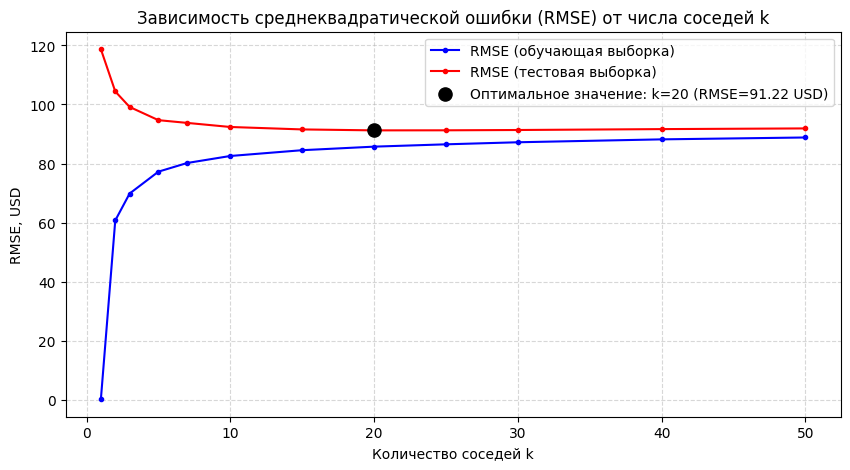

In [151]:
best_idx = np.argmin(test_rmse_list)
best_k = k_arr[best_idx]
best_test_rmse = test_rmse_list[best_idx]
plt.figure(figsize=(10, 5))
plt.plot(k_arr, train_rmse_list, 'b.-', label='RMSE (обучающая выборка)')
plt.plot(k_arr, test_rmse_list,  'r.-', label='RMSE (тестовая выборка)')
plt.scatter([best_k], [best_test_rmse], color='black', s=90, zorder=5,
            label=f'Оптимальное значение: k={best_k} (RMSE={best_test_rmse:.2f} USD)')
plt.title('Зависимость среднеквадратической ошибки (RMSE) от числа соседей k')
plt.xlabel('Количество соседей k')
plt.ylabel('RMSE, USD')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
pass

In [152]:
best_knn = KNeighborsRegressor(n_neighbors=best_k, n_jobs=-1)
best_knn.fit(X_train, y_train)
y_train_best_pred = best_knn.predict(X_train)
y_test_best_pred  = best_knn.predict(X_test)
final_knn_metrics = pd.DataFrame({
    'Train': [
        mean_squared_error(y_train, y_train_best_pred)**0.5,
        mean_absolute_error(y_train, y_train_best_pred),
        r2_score(y_train, y_train_best_pred)
    ],
    'Test': [
        mean_squared_error(y_test, y_test_best_pred)**0.5,
        mean_absolute_error(y_test, y_test_best_pred),
        r2_score(y_test, y_test_best_pred)
    ]
}, index=['RMSE', 'MAE', 'R^2'])
print(f"Итоговые ошибки kNN при оптимальном k = {best_k}:")
display(final_knn_metrics.round(2))

Итоговые ошибки kNN при оптимальном k = 20:


,Train,Test
RMSE,85.71,91.22
MAE,48.53,50.95
R^2,0.46,0.40


**При $k = 1$** — сильное переобучение, большое влияние шума.  
**С увеличением $k$ от 1 до 20** происходит усреднение по большему числу соседей, влияние шума уменьшается, и ошибка на тесте монотонно убывает.  
**При $k > 20$** — недообучение, ошибка на тесте начинает медленно расти, алгоритм захватывает слишком далёкие и разнородные помещения.  
**Оптимальным значением является $k = 20$**. При нём достигается глобальный минимум ошибки прогнозирования на новых данных **RMSE = 91.22 USD**, модель в среднем ошибается в определении суточной стоимости аренды примерно на 51 доллар **MAE = 50.95 USD** и объясняет 40% вариации стоимости жилья в Нью-Йорке на основе имеющихся признаков **$R^2 = 0.40$**.

### **10. Обучение других моделей регрессии. Сравнение результатов**

Для сравнения с методом ближайших соседей $k\text{NN}$ обучим Линейную регрессию **LinearRegression** и Случайный лес **RandomForestRegressor** .

In [153]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train, y_train)
y_train_lr = lr.predict(X_train)
y_test_lr  = lr.predict(X_test)
lr_metrics = {
    'Train RMSE': mean_squared_error(y_train, y_train_lr)**0.5,
    'Test RMSE':  mean_squared_error(y_test, y_test_lr)**0.5,
    'Train MAE':  mean_absolute_error(y_train, y_train_lr),
    'Test MAE':   mean_absolute_error(y_test, y_test_lr),
    'Train R^2':  r2_score(y_train, y_train_lr),
    'Test R^2':   r2_score(y_test, y_test_lr)
}

In [154]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(n_estimators=100, max_depth=16, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_train_rf = rf.predict(X_train)
y_test_rf  = rf.predict(X_test)
rf_metrics = {
    'Train RMSE': mean_squared_error(y_train, y_train_rf)**0.5,
    'Test RMSE':  mean_squared_error(y_test, y_test_rf)**0.5,
    'Train MAE':  mean_absolute_error(y_train, y_train_rf),
    'Test MAE':   mean_absolute_error(y_test, y_test_rf),
    'Train R^2':  r2_score(y_train, y_train_rf),
    'Test R^2':   r2_score(y_test, y_test_rf)
}

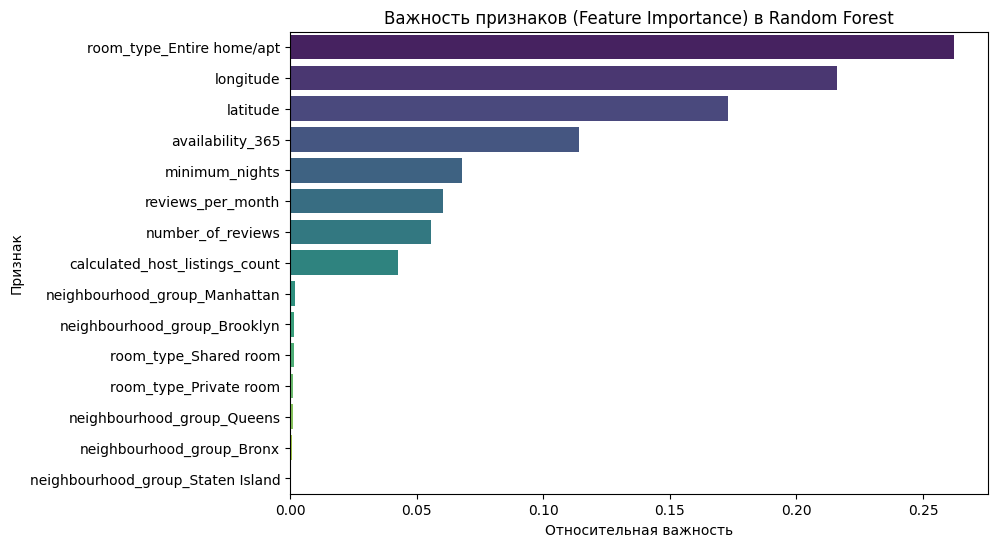

In [157]:
rf_importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
plt.figure(figsize=(9, 6))
sns.barplot(x=rf_importances.values, y=rf_importances.index, hue=rf_importances.index, palette='viridis', legend=False)
plt.title('Важность признаков (Feature Importance) в Random Forest')
plt.xlabel('Относительная важность')
plt.ylabel('Признак')
pass

Самые важные признаки: тип жилья, его координаты, то есть местоположение и количество доступных дней в течение года.

In [155]:
knn_metrics = {
    'Train RMSE': mean_squared_error(y_train, y_train_best_pred)**0.5,
    'Test RMSE':  mean_squared_error(y_test, y_test_best_pred)**0.5,
    'Train MAE':  mean_absolute_error(y_train, y_train_best_pred),
    'Test MAE':   mean_absolute_error(y_test, y_test_best_pred),
    'Train R^2':  r2_score(y_train, y_train_best_pred),
    'Test R^2':   r2_score(y_test, y_test_best_pred)
}
comparison_df = pd.DataFrame({
    'kNN (k=20)': knn_metrics,
    'Linear Regression': lr_metrics,
    'Random Forest': rf_metrics
}).T
print("Сводная таблица сравнения моделей машинного обучения:")
display(comparison_df.round(2))

Сводная таблица сравнения моделей машинного обучения:


,Train RMSE,Test RMSE,Train MAE,Test MAE,Train R^2,Test R^2
kNN (k=20),85.71,91.22,48.53,50.95,0.46,0.40
Linear Regression,97.09,97.87,57.49,57.22,0.31,0.31
Random Forest,50.10,88.10,30.47,49.05,0.82,0.44


1. **Линейная регрессия** (Linear Regression) показала самый плохой результат: на тестовой выборке у неё большие ошибки и небольшой коэффициент детерминации. Ошибки на обучении и тесте равны ($R^2 = 0.31$), поэтому здесь присутствует недообучение.  
2. **Метод ближайших соседей** $k\text{NN}$ показал заметно лучший результат по сравнению с линейной регрессией, так как он успешно использует географическую близость и схожесть параметров жилья.  
3. **Случайный лес** (Random Forest) показал самый лучший результат среди всех моделей, обеспечил наилучшую точность, так как ансамбль решающих деревьев наиболее эффективно уловил нелинейные зависимости и сложные пороговые правила, но разрыв между качеством на обучении $\text{Train } R^2 = 0.82$ и тесте $\text{Test } R^2 = 0.44$ показывает склонность к частичному переобучению.

### **11. Несбалансированность классов**

В данной работе решается задача регрессии, поэтому несбалансированности классов здесь нет.

### **12. Исключение коррелированных переменных**

В ходе корреляционного анализа в пункте  была зафиксирована заметная корреляция ($r = 0.5$) между признаками `number_of_reviews` и `reviews_per_month`. В методе $k\text{NN}$ это искусственно удваивает вклад фактора отзывов при расчете евклидова расстояния, искажая геометрию пространства.
Удалим признак `reviews_per_month` и оценим влияние на качество модели.

In [158]:
X_train_uncorr = X_train.drop(columns=['reviews_per_month'])
X_test_uncorr  = X_test.drop(columns=['reviews_per_month'])
knn_uncorr = KNeighborsRegressor(n_neighbors=20, n_jobs=-1)
knn_uncorr.fit(X_train_uncorr, y_train)
y_test_pred_uncorr = knn_uncorr.predict(X_test_uncorr)
rmse_uncorr = mean_squared_error(y_test, y_test_pred_uncorr)**0.5
mae_uncorr  = mean_absolute_error(y_test, y_test_pred_uncorr)
r2_uncorr   = r2_score(y_test, y_test_pred_uncorr)
corr_comparison = pd.DataFrame({
    'Со всеми признаками (15 шт.)': [91.22, 50.95, 0.40],
    'Без reviews_per_month (14 шт.)': [rmse_uncorr, mae_uncorr, r2_uncorr]
}, index=['Test RMSE (USD)', 'Test MAE (USD)', 'Test R^2'])
print("Сравнение качества kNN до и после удаления коррелирующего признака:")
display(corr_comparison.round(2))

Сравнение качества kNN до и после удаления коррелирующего признака:


,Со всеми признаками (15 шт.),Без reviews_per_month (14 шт.)
Test RMSE (USD),91.22,91.10
Test MAE (USD),50.95,50.88
Test R^2,0.40,0.40


Исключение коррелирующего признака `reviews_per_month` положительно сказалось на модели:  
* Ошибка на тестовой выборке незначительно снизилась: Test RMSE уменьшилась **с 91.22 до 91.10 USD**, а Test MAE — **с 50.95 до 50.88 USD**;  
* Коэффициент детерминации сохранился на уровне $R^2 = 0.40$;  
* Устранение мультиколлинеарности избавило метрику евклидова расстояния в $k\text{NN}$ от двойного учета активности отзывов, снизило размерность пространства и ускорило работу алгоритма без малейшей потери качества.

### **13. Общие выводы**

В ходе выполнения данной работы был проведён анализ данных и были построены некоторые модели машинного обучения для решения задачи регрессии, которая заключалась в прогнозировании суточной стоимости аренды жилья в Нью-Йорке на основе данных 2019 года, взятых с Airbnb. Была проведена предобработка данных, очистка их от шума, а точнее удаление неинформативных признаков, опечаток, ошибок ввода, работа с выбросами и пропущенными значениями, кодировка и масштабирование признаков. Были рассмотрены и проанализированы метод ближайших соседей, линейная регрессия и случайный лес. Самый лучший результат показал случайный лес. Также был сделан анализ важности признаков, который показал, что стоимость аренды в основном зависит от типа жилья и его местоположения, а исключение сильно коррелирующего признака устранило дублирование информации, избавило модель от мультиколлинеарности и снизило ошибку в методе ближайших соседей при уменьшении размерности.